# Fig. 5 — θ(Q) and the Q dependence of the ∂θ/∂Q estimate (paper `draft/main_draft.tex`, `fig:thetaQ`)

One column, two panels; Q = displacement per Cartesian component of the raw SMODES vector v (entries ±1).

* **(a)** Y₂Ir₂O₇ θ(Q) = θ_CS(displaced) − θ_CS(undistorted) from the Chern–Simons 3-form (points; nk 12;
  `cs_theta.sh`, 2026-11-02) for the three Γ₂⁻ basis patterns (1: Y, 2: Ir, 3: O 48f), against Q·∂θ/∂Q|₀ with the
  four-curvature slope (lines). θ is odd under inversion: the Q < 0 points are θ(−Q) = −θ(Q).
* **(b)** Each estimate divided by its own Q → 0 limit: the Y₂Ir₂O₇ 3-form chord θ(Q)/Q (filled; fit a + bQ² + cQ⁴,
  whose intercept reproduces the four-curvature slope to 1e-5), the Y₂Ir₂O₇ four-curvature estimate with the undistorted
  model's momentum-space quantities (open squares), and the same estimate for MnBi₂Te₄ pattern 3 (Te1), the pattern with
  two amplitudes (0.01, 0.03 Å; open diamonds, a + bQ²). The undistorted-end estimate moves by at most 1.2% at
  0.05 Å in Y₂Ir₂O₇ (pattern 1; ≤ 0.15% at 0.02 Å) and by 0.4% at 0.03 Å in MnBi₂Te₄; the chord departs from 1 by
  the nonlinearity of θ(Q).

The displaced-end estimates (the momentum-space quantities of the displaced model) converge to the same limits, with a
difference ∝ Q² (MnBi₂Te₄ pattern 3: 2.4% at 0.01 Å, 23% at 0.03 Å); they are printed by the data cell and quoted in
the text, not drawn. ΔE(Q) against the forces (the old panels a, d) is Fig. 9 (`fig9.ipynb`, appendix).

Four-curvature values: `dtheta.npz` of each pair (pipeline steps 3-7). Y₂Ir₂O₇: window f12.422_w22.644_k8, base 220455,
10³ grid, 2026-11-02. MnBi₂Te₄: window f10.962_w12.810_k8, production tube (16, 4, 3, 8), 2026-10-30.

In [1]:
# ---- settings
from pathlib import Path
ROOT = Path("/Users/treycole/Repos/axion-phonon")
DATA = ROOT / "data"
# Y2Ir2O7
YIO = DATA / "Y2Ir2O7"
PATTERNS = (1, 2, 3)
QS = (0.01, 0.02, 0.03, 0.05)                # Å; structure folders GM2-_p<m>_Q<q>
WINDOW = YIO / "windows/f12.422_w22.644_k8"
C2 = "dtheta_GM2-_p{m}_Q{q:.2f}/dtheta.npz"  # four-curvature, both ends (step 7), in WINDOW
C2_FIT_DEGREE = 2                            # each end fitted to a + bQ² (1) or a + bQ² + cQ⁴ (2)
THETA = "dtheta_GM2-_p{m}_Q{q:.2f}/cs/theta_cs.npz"   # 3-form θ of the structure and the base (cs_theta_sum.sh), in WINDOW
THETA_NK = 12                                # 10 or 12 (identical to 1e-6)
THETA_FIT_DEGREE = 2                         # θ/Q = a + bQ² + cQ⁴ (2) or a + bQ² (1)
LABELS = {1: "Y", 2: "Ir", 3: r"O$_{48f}$"}
COLORS = {1: "#2b6cb0", 2: "#7b3294", 3: "#d9821e"}   # shared palette by role: Y blue, Ir purple, O orange
# MnBi2Te4
MBT_WINDOW = DATA / "MnBi2Te4/windows/f10.962_w12.810_k8"
MBT_C2 = {(m, q): MBT_WINDOW / f"dtheta_T2-_p{m}_Q{q:.2f}/dtheta.npz"     # every pattern at 0.01 Å, pattern 3 also at 0.03
          for m, q in [(1, 0.01), (2, 0.01), (3, 0.01), (4, 0.01), (3, 0.03)]}
MBT_PATTERN = 3                              # the pattern with two amplitudes
MBT_LABEL = r"MnBi$_2$Te$_4$ Te1"
MBT_COLOR = "#d9821e"                        # Te1 (anion role); told apart from O by the marker
FIGSIZE = (3.4, 4.3)                         # inches; one column
FONT_SIZE = 8
SAVE_FIG = ROOT / "paper/figures/fig5.pdf"   # or None
# ---------------

In [2]:
# ---- data: four-curvature ends, 3-form θ(Q)
import numpy as np
import matplotlib.pyplot as plt

ends, limits, slope = {}, {}, {}             # pattern: (Q, end) array; Q -> 0 per end; mean of the two
for m in PATTERNS:
    qs = np.array(QS)
    ends[m] = np.array([np.load(WINDOW / C2.format(m=m, q=q))["dtheta"][0, 0].real for q in qs])
    limits[m] = [np.polyfit(qs ** 2, ends[m][:, e], C2_FIT_DEGREE)[-1] for e in (0, 1)]
    slope[m] = float(np.mean(limits[m]))
    print(f"Y2Ir2O7 pattern {m}: Q -> 0 undistorted end {limits[m][0]:+.6f}, displaced end {limits[m][1]:+.6f}; "
          f"undistorted end / limit - 1 at {QS[-1]} Å {100 * (ends[m][-1, 0] / limits[m][0] - 1):+.2f}%, "
          f"displaced end {100 * (ends[m][-1, 1] / limits[m][1] - 1):+.2f}%")
theta, intercept = {}, {}                    # pattern: (Q, θ(Q) − θ(0)); fit of θ/Q in Q²
for m in PATTERNS:
    rows = []
    for q in QS:
        z = np.load(WINDOW / THETA.format(m=m, q=q))
        i = list(z["nks"]).index(THETA_NK)
        rows.append((q, float(z["theta_mode"][i].real - z["theta_base"][i].real)))
    theta[m] = np.array(rows).T
    qs, th = theta[m]
    intercept[m] = np.polyfit(qs ** 2, th / qs, THETA_FIT_DEGREE)
    print(f"Y2Ir2O7 pattern {m}: 3-form intercept {intercept[m][-1]:+.6f} vs four-curvature {slope[m]:+.6f} "
          f"({100 * (intercept[m][-1] / slope[m] - 1):+.4f}%); chord / slope - 1 at {qs[-1]} Å "
          f"{100 * (th[-1] / qs[-1] / slope[m] - 1):+.2f}%")
mbt_ends = {key: np.load(f)["dtheta"][-1, 0].real for key, f in MBT_C2.items()}   # finest level, all planes: (base, structure)
q3 = np.array([0.01, 0.03])
e3 = np.array([mbt_ends[(MBT_PATTERN, q)] for q in q3])            # (Q, end)
mbt_fit = [np.polyfit(q3 ** 2, e3[:, e], 1) for e in (0, 1)]        # a + bQ² through the two amplitudes, per end
for key, (b, s) in sorted(mbt_ends.items()):
    print(f"MnBi2Te4 pattern {key[0]}, Q = {key[1]}: undistorted end {b:+.5f}, displaced end {s:+.5f} rad/Å "
          f"(difference {100 * (s / b - 1):+.2f}%)")
print(f"MnBi2Te4 pattern {MBT_PATTERN}, Q -> 0 (a + bQ²): undistorted end {mbt_fit[0][-1]:.4f}, displaced end "
      f"{mbt_fit[1][-1]:.4f} rad/Å; undistorted end / limit - 1 at 0.03 Å {100 * (e3[1, 0] / mbt_fit[0][-1] - 1):+.2f}%")

Y2Ir2O7 pattern 1: Q -> 0 undistorted end -0.017119, displaced end -0.017120; undistorted end / limit - 1 at 0.05 Å -1.24%, displaced end +13.25%
Y2Ir2O7 pattern 2: Q -> 0 undistorted end +0.055038, displaced end +0.055036; undistorted end / limit - 1 at 0.05 Å -0.46%, displaced end -11.82%
Y2Ir2O7 pattern 3: Q -> 0 undistorted end +0.063880, displaced end +0.063880; undistorted end / limit - 1 at 0.05 Å -0.72%, displaced end -2.23%
Y2Ir2O7 pattern 1: 3-form intercept -0.017120 vs four-curvature -0.017120 (+0.0004%); chord / slope - 1 at 0.05 Å +0.54%
Y2Ir2O7 pattern 2: 3-form intercept +0.055037 vs four-curvature +0.055037 (+0.0006%); chord / slope - 1 at 0.05 Å -3.07%
Y2Ir2O7 pattern 3: 3-form intercept +0.063880 vs four-curvature +0.063880 (+0.0001%); chord / slope - 1 at 0.05 Å -1.62%
MnBi2Te4 pattern 1, Q = 0.01: undistorted end -1.95890, displaced end -1.95500 rad/Å (difference -0.20%)
MnBi2Te4 pattern 2, Q = 0.01: undistorted end +3.81959, displaced end +3.87149 rad/Å (differenc

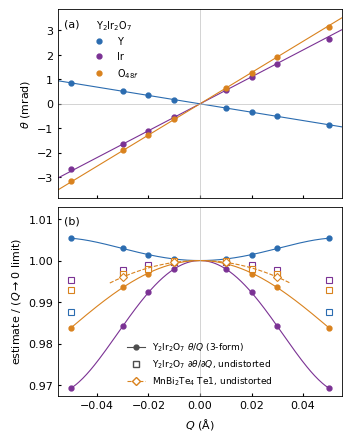

In [3]:
# ---- draw
plt.rcParams.update({"font.size": FONT_SIZE, "axes.linewidth": 0.6})
fig, (ax_t, ax_r) = plt.subplots(2, 1, figsize=FIGSIZE, sharex=True, layout="constrained")
q = np.linspace(-0.055, 0.055, 221)
for m in PATTERNS:
    c = COLORS[m]
    qs, th = theta[m]
    ax_t.plot(q, 1e3 * q * slope[m], color=c, lw=0.8)
    ax_t.plot(np.r_[-qs, qs], 1e3 * np.r_[-th, th], "o", ms=3.5, color=c, label=LABELS[m])
    q_fit = q[np.abs(q) <= qs.max()]                       # the fit only where there are data
    ax_r.plot(q_fit, np.polyval(intercept[m], q_fit ** 2) / slope[m], color=c, lw=0.8)
    ax_r.plot(np.r_[-qs, qs], np.r_[th / qs, th / qs] / slope[m], "o", ms=3.5, color=c)
    r = ends[m][:, 0] / limits[m][0]
    ax_r.plot(np.r_[-qs, qs], np.r_[r, r], "s", ms=4, mfc="white", mec=c, mew=0.8)
r = e3[:, 0] / mbt_fit[0][-1]
q_m = q[np.abs(q) <= 0.035]
ax_r.plot(q_m, np.polyval(mbt_fit[0], q_m ** 2) / mbt_fit[0][-1], color=MBT_COLOR, lw=0.8, ls="--")
ax_r.plot(np.r_[-q3, q3], np.r_[r, r], "D", ms=4, mfc="white", mec=MBT_COLOR, mew=0.8)
ax_t.legend(fontsize=FONT_SIZE - 1, frameon=False, loc="upper left", bbox_to_anchor=(0.08, 1.0),
            title=r"Y$_2$Ir$_2$O$_7$", title_fontsize=FONT_SIZE - 1)
ax_t.set_ylabel(r"$\theta$ (mrad)")
ax_t.axhline(0, color="0.7", lw=0.4)
handles = [plt.Line2D([], [], color="0.3", marker="o", ms=3.5, lw=0.8, label=r"Y$_2$Ir$_2$O$_7$ $\theta/Q$ (3-form)"),
           plt.Line2D([], [], color="0.3", marker="s", ms=4, mfc="white", lw=0,
                      label=r"Y$_2$Ir$_2$O$_7$ $\partial\theta/\partial Q$, undistorted"),
           plt.Line2D([], [], color=MBT_COLOR, marker="D", ms=4, mfc="white", lw=0.8, ls="--",
                      label=MBT_LABEL + r", undistorted")]
ax_r.legend(handles=handles, fontsize=FONT_SIZE - 1.5, frameon=False, loc="lower center")
ax_r.set_ylabel("estimate / ($Q\\to0$ limit)")
ax_r.set_xlabel(r"$Q$ (Å)")
ax_r.set_xlim(q[0], q[-1])
ax_r.set_ylim(top=1.013)                    # room for the panel tag
for ax, tag in zip((ax_t, ax_r), "ab"):
    ax.axvline(0, color="0.7", lw=0.4)
    ax.tick_params(direction="in", length=2, which="both")
    ax.text(0.02, 0.95, f"({tag})", transform=ax.transAxes, va="top", fontsize=FONT_SIZE)
if SAVE_FIG:
    SAVE_FIG.parent.mkdir(exist_ok=True)
    fig.savefig(SAVE_FIG)
    fig.savefig(SAVE_FIG.with_suffix(".png"), dpi=300)
plt.show()
plt.rcdefaults()